# Task 4.1 — Epidemia y camas de contingencia

Extiende el hospital **sin espera** (M(t)/M/c/c) acoplando una ola SIR unidireccional a las llegadas. No modifica Tasks 1–3.

Parámetros: $N=500000$, $\beta=0.30$, $\gamma=0.20$, $I_0=100$, $p_h=0.0002$, $\lambda_{\mathrm{base}}=3.6$, $\mu=0.25$, $t_{\mathrm{final}}=200$, $c_{\mathrm{base}}=22$ (Task 3.1 sin espera), $n_{\mathrm{reps}}=100$, meta de desvío agregado $\le 5\,\%$, `master_seed=20261020`.



## Preparación

Se reutiliza la idea del DES de Tasks 1–3 (heap de altas, sistema sin cola). Las llegadas epidémicas son un Poisson no homogéneo generado por **adelgazamiento**. El hospital se precalienta con demanda base antes de $t=0$.


In [1]:
import heapq
import math
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import integrate, optimize, stats
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

OUT = Path('resultados/task4')
OUT.mkdir(parents=True, exist_ok=True)
Path('figuras').mkdir(exist_ok=True)

# Parámetros obligatorios
N = 500_000
BETA = 0.30
GAMMA = 0.20
I0 = 100
R0 = 0
S0 = N - I0 - R0
P_H = 0.0002
LAM_BASE = 3.6
MU = 0.25
T_FINAL = 200.0
C_BASE = 22
N_REPS = 100
META_DESVIO = 0.05
BIN_WIDTH = 1.0
MASTER_SEED = 20261020
WARMUP_DAYS = 1000.0

assert S0 == 499900
assert C_BASE == 22  # recomendación Task 3.1 sin espera

def replica_seeds(n, master_seed=MASTER_SEED):
    ss = np.random.SeedSequence(master_seed)
    return [int(c.generate_state(1)[0]) for c in ss.spawn(n)]

def ic95_t(xs):
    xs = np.asarray(xs, dtype=float)
    xs = xs[np.isfinite(xs)]
    assert len(xs) >= 2
    m = float(xs.mean())
    s = float(xs.std(ddof=1))
    half = float(stats.t.ppf(0.975, len(xs) - 1) * s / math.sqrt(len(xs)))
    return dict(media=m, std=s, semiancho=half, inferior=m - half, superior=m + half, n=len(xs))

print('Salida:', OUT.resolve())
print('Semillas de prueba:', replica_seeds(3)[:3])


Salida: /home/cisco/universidad/cuarto/segundo_semestre/modelacion_sim/hdt7/HT7-MS/resultados/task4
Semillas de prueba: [2813617838, 867761043, 2048843007]


## Task 4.1(a) — SIR y tasa epidémica de llegadas

$$
\frac{dS}{dt}=-\beta\frac{SI}{N},\quad
\frac{dI}{dt}=\beta\frac{SI}{N}-\gamma I,\quad
\frac{dR}{dt}=\gamma I.
$$

Incidencia $\beta S I/N$; llegadas epidémicas $\lambda_{\mathrm{epi}}(t)=p_h\cdot\mathrm{incidencia}(t)$; total $\lambda_{\mathrm{total}}(t)=3.6+\lambda_{\mathrm{epi}}(t)$.


Conservación max|S+I+R-N| = 4.075e-10
Pico continuo: t=68.6367 d, lambda_epi=1.321268
Pico malla:     t=68.6400 d, lambda_epi=1.321268


,parametro,valor
0,N,500000
1,beta,0.3
2,gamma,0.2
3,"S0,I0,R0","499900,100,0"
4,p_h,0.0002
5,lambda_base,3.6


,dia_pico,dia_pico_redondeado,lambda_epi_pico,lambda_total_pico,infecciones_acumuladas,llegadas_epidemicas_esperadas,llegadas_totales_esperadas
0,68.636672,69,1.321268,4.921268,291404.241736,58.280848,778.280848


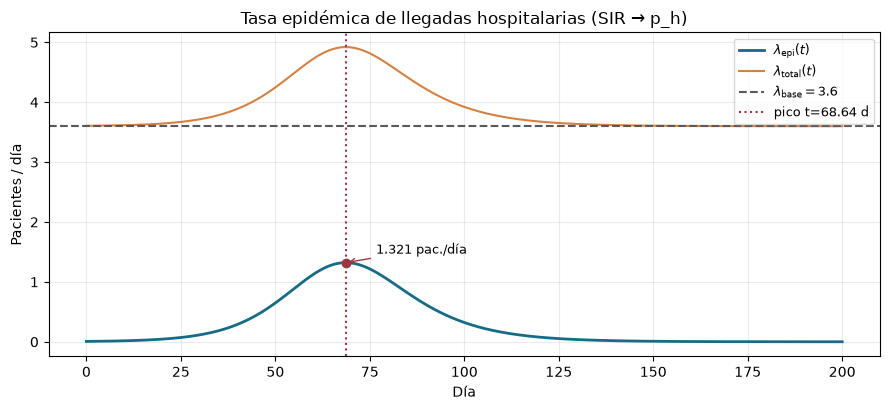

Guardado task4_sir_llegadas.csv y task4_sir_pico.png


In [2]:
def sir_ode(t, y):
    S, I, R = y
    inf = BETA * S * I / N
    return [-inf, inf - GAMMA * I, GAMMA * I]

sol = integrate.solve_ivp(
    sir_ode, (0.0, T_FINAL), [S0, I0, R0],
    method='RK45', rtol=1e-8, atol=1e-10, dense_output=True,
)
assert sol.success, sol.message

def SIR(t):
    t_arr = np.atleast_1d(np.asarray(t, dtype=float))
    y = sol.sol(t_arr)
    S, I, R = y[0], y[1], y[2]
    if np.size(t_arr) == 1 and np.ndim(t) == 0:
        return float(S[0]), float(I[0]), float(R[0])
    return S, I, R

def incidencia(t):
    S, I, _ = SIR(t)
    return BETA * S * I / N

def lambda_epi(t):
    return P_H * incidencia(t)

def lambda_total(t):
    return LAM_BASE + lambda_epi(t)

# Malla diaria para CSV y verificaciones
dias = np.arange(0, T_FINAL + 1e-12, BIN_WIDTH)
S, I, R = SIR(dias)
inc = BETA * S * I / N
le = P_H * inc
lt = LAM_BASE + le
pob = S + I + R
assert np.all(S >= -1e-6) and np.all(I >= -1e-6) and np.all(R >= -1e-6)
assert np.max(np.abs(pob - N)) < 1e-4
print(f'Conservación max|S+I+R-N| = {np.max(np.abs(pob - N)):.3e}')

# Pico continuo de lambda_epi
res_max = optimize.minimize_scalar(lambda t: -lambda_epi(t), bounds=(0, T_FINAL), method='bounded',
                                   options={'xatol': 1e-10})
t_pico = float(res_max.x)
le_pico = float(lambda_epi(t_pico))
# contraste malla densa
td = np.linspace(0, T_FINAL, 20001)
le_d = lambda_epi(td)
ix = int(np.argmax(le_d))
print(f'Pico continuo: t={t_pico:.4f} d, lambda_epi={le_pico:.6f}')
print(f'Pico malla:     t={td[ix]:.4f} d, lambda_epi={float(le_d[ix]):.6f}')
assert abs(t_pico - td[ix]) < 0.05
assert 60 < t_pico < 80 and 1.0 < le_pico < 1.6  # entorno de la referencia ~68.6 / 1.32

infecciones_acum = float(integrate.quad(incidencia, 0, T_FINAL, epsabs=1e-8)[0])
llegadas_epi_esp = float(integrate.quad(lambda_epi, 0, T_FINAL, epsabs=1e-8)[0])
llegadas_tot_esp = LAM_BASE * T_FINAL + llegadas_epi_esp

df_sir = pd.DataFrame({
    'dia': dias, 'S': S, 'I': I, 'R': R,
    'incidencia': inc, 'lambda_epi': le, 'lambda_total': lt,
})
df_sir.to_csv(OUT / 'task4_sir_llegadas.csv', index=False)

tabla_pico = pd.DataFrame([{
    'dia_pico': t_pico,
    'dia_pico_redondeado': round(t_pico),
    'lambda_epi_pico': le_pico,
    'lambda_total_pico': LAM_BASE + le_pico,
    'infecciones_acumuladas': infecciones_acum,
    'llegadas_epidemicas_esperadas': llegadas_epi_esp,
    'llegadas_totales_esperadas': llegadas_tot_esp,
}])
display(pd.DataFrame([
    {'parametro': 'N', 'valor': N}, {'parametro': 'beta', 'valor': BETA},
    {'parametro': 'gamma', 'valor': GAMMA}, {'parametro': 'S0,I0,R0', 'valor': f'{S0},{I0},{R0}'},
    {'parametro': 'p_h', 'valor': P_H}, {'parametro': 'lambda_base', 'valor': LAM_BASE},
]))
display(tabla_pico)

fig, ax = plt.subplots(figsize=(9, 4.2))
tt = np.linspace(0, T_FINAL, 2001)
ax.plot(tt, lambda_epi(tt), color='#176b87', lw=2, label=r'$\lambda_{\mathrm{epi}}(t)$')
ax.plot(tt, lambda_total(tt), color='#cd6b23', lw=1.5, alpha=.85, label=r'$\lambda_{\mathrm{total}}(t)$')
ax.axhline(LAM_BASE, color='0.35', ls='--', label=fr'$\lambda_{{\mathrm{{base}}}}={LAM_BASE}$')
ax.axvline(t_pico, color='#9c3742', ls=':', label=f'pico t={t_pico:.2f} d')
ax.scatter([t_pico], [le_pico], color='#9c3742', zorder=3)
ax.annotate(f'{le_pico:.3f} pac./día', xy=(t_pico, le_pico), xytext=(t_pico + 8, le_pico + 0.15),
            fontsize=9, arrowprops=dict(arrowstyle='->', color='#9c3742'))
ax.set(xlabel='Día', ylabel='Pacientes / día',
       title='Tasa epidémica de llegadas hospitalarias (SIR → p_h)')
ax.grid(alpha=.25); ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(OUT / 'task4_sir_pico.png', dpi=150)
fig.savefig('figuras/task4_sir_pico.png', dpi=150)
plt.show()
print('Guardado task4_sir_llegadas.csv y task4_sir_pico.png')


## Task 4.1(b) — Thinning NHPP, hospital sin espera y 100 réplicas

Cota $M\ge\max_t\lambda_{\mathrm{total}}(t)$ (con margen). Calentamiento 1000 días con $\lambda=3.6$ antes de $t=0$; solo se conservan ocupación y altas pendientes. Métricas de la ola en $[0,200]$.


In [3]:
def max_lambda_total(t0=0.0, t1=T_FINAL):
    """Máximo continuo de lambda_total en [t0,t1] (minimizar el negativo)."""
    res = optimize.minimize_scalar(lambda t: -lambda_total(t), bounds=(t0, t1), method='bounded',
                                   options={'xatol': 1e-12})
    # también extremos
    vals = [lambda_total(t0), lambda_total(t1), float(-res.fun)]
    return max(vals)

M_RATE = max_lambda_total() * 1.001
print(f'Cota M = {M_RATE:.6f} (pico total ≈ {LAM_BASE + le_pico:.6f})')
assert M_RATE >= LAM_BASE + le_pico


def thinning_arrivals(t0, t1, lam_fn, M, rng):
    """Poisson no homogéneo por adelgazamiento en [t0, t1)."""
    t = t0
    times = []
    while True:
        t += rng.exponential(1.0 / M)
        if t >= t1:
            break
        lt = float(lam_fn(t))
        if lt > M + 1e-12:
            raise RuntimeError(f'lambda_total({t})={lt} > M={M}')
        if rng.uniform() < lt / M:
            times.append(t)
    return np.asarray(times, dtype=float)


def warmup_occupancy(c, lam, mu, warmup, rng):
    """Estado estacionario aproximado con demanda base; no cuenta métricas."""
    departures = []
    busy = 0
    t = 0.0
    while True:
        gap = rng.exponential(1.0 / lam)
        t += gap
        if t >= warmup:
            # avanzar altas hasta el fin del calentamiento
            while departures and departures[0] <= warmup:
                heapq.heappop(departures)
                busy -= 1
            # desplazar altas restantes a tiempo relativo t'=0
            pending = [d - warmup for d in departures]
            heapq.heapify(pending)
            assert 0 <= busy <= c
            return busy, pending
        while departures and departures[0] <= t:
            heapq.heappop(departures)
            busy -= 1
        if busy < c:
            busy += 1
            heapq.heappush(departures, t + rng.exponential(1.0 / mu))


def simulate_wave(c, arrival_times, service_times, busy0, pending0, t_final=T_FINAL, n_days=200):
    """Hospital sin espera en [0,t_final) con llegadas y estancias pregeneradas (CRN)."""
    pending = list(pending0)
    heapq.heapify(pending)
    busy = busy0
    llegadas = np.zeros(n_days, dtype=int)
    desviados = np.zeros(n_days, dtype=int)
    admitidos = np.zeros(n_days, dtype=int)
    for i, t in enumerate(arrival_times):
        if t >= t_final:
            break
        while pending and pending[0] <= t:
            heapq.heappop(pending)
            busy -= 1
        day = int(math.floor(t))
        if day >= n_days:
            continue
        llegadas[day] += 1
        if busy < c:
            busy += 1
            admitidos[day] += 1
            heapq.heappush(pending, t + service_times[i])
        else:
            desviados[day] += 1
        assert 0 <= busy <= c
    assert np.all(admitidos + desviados == llegadas)
    return dict(llegadas=llegadas, desviados=desviados, admitidos=admitidos,
                total_llegadas=int(llegadas.sum()), total_desviados=int(desviados.sum()),
                total_admitidos=int(admitidos.sum()),
                fraccion=float(desviados.sum() / llegadas.sum()) if llegadas.sum() else float('nan'))


# --- Prueba thinning con tasa constante ---
rng_test = np.random.default_rng(12345)
Ttest = 500.0
lam_c = 3.6
arr_c = thinning_arrivals(0, Ttest, lambda t: lam_c, lam_c * 1.001, rng_test)
esperadas = lam_c * Ttest
print(f'Thinning constante: n={len(arr_c)}, esperado≈{esperadas:.1f}, '
      f'z≈{(len(arr_c)-esperadas)/math.sqrt(esperadas):.2f}')
assert abs(len(arr_c) - esperadas) < 4 * math.sqrt(esperadas)

# Prueba hospital: identidad admitidos+desviados
rng_w = np.random.default_rng(7)
b0, p0 = warmup_occupancy(5, LAM_BASE, MU, 200, rng_w)
arr = thinning_arrivals(0, 50, lambda_total, M_RATE, rng_w)
srv = rng_w.exponential(1 / MU, size=len(arr))
r = simulate_wave(5, arr, srv, b0, p0, t_final=50, n_days=50)
assert r['total_admitidos'] + r['total_desviados'] == r['total_llegadas']
assert 0 <= r['fraccion'] <= 1
print('PASA: thinning constante y balance admitidos+desviados.')


Cota M = 4.926190 (pico total ≈ 4.921268)
Thinning constante: n=1868, esperado≈1800.0, z≈1.60
PASA: thinning constante y balance admitidos+desviados.


In [4]:
def generar_replicas_llegadas(n_reps=N_REPS, master_seed=MASTER_SEED):
    """Llegadas + estancias + estado inicial por réplica (CRN entre capacidades)."""
    seeds = replica_seeds(n_reps, master_seed)
    packs = []
    for seed in seeds:
        # tres streams independientes derivados de la semilla de réplica
        ss = np.random.SeedSequence(seed)
        s_warm, s_arr, s_srv = ss.spawn(3)
        rng_w = np.random.default_rng(s_warm)
        rng_a = np.random.default_rng(s_arr)
        rng_s = np.random.default_rng(s_srv)
        busy0, pending0 = warmup_occupancy(C_BASE, LAM_BASE, MU, WARMUP_DAYS, rng_w)
        # Nota: el calentamiento usa C_BASE solo para estado; al cambiar c se
        # re-calienta con la c evaluada (abajo). Las LLEGADAS sí se fijan por CRN.
        arrivals = thinning_arrivals(0.0, T_FINAL, lambda_total, M_RATE, rng_a)
        services = rng_s.exponential(1.0 / MU, size=len(arrivals))
        packs.append(dict(seed=seed, arrivals=arrivals, services=services,
                          # warm state se regenera por c en run_capacity
                          ))
    return seeds, packs


def warmup_for_c(c, seed):
    ss = np.random.SeedSequence(seed)
    s_warm, _, _ = ss.spawn(3)
    rng_w = np.random.default_rng(s_warm)
    return warmup_occupancy(c, LAM_BASE, MU, WARMUP_DAYS, rng_w)


def run_capacity(c, packs, seeds):
    rows = []
    L = np.zeros((len(packs), 200), dtype=int)
    D = np.zeros((len(packs), 200), dtype=int)
    A = np.zeros((len(packs), 200), dtype=int)
    for r, (pack, seed) in enumerate(zip(packs, seeds)):
        busy0, pending0 = warmup_for_c(c, seed)
        out = simulate_wave(c, pack['arrivals'], pack['services'], busy0, pending0)
        L[r] = out['llegadas']; D[r] = out['desviados']; A[r] = out['admitidos']
        assert out['total_admitidos'] + out['total_desviados'] == out['total_llegadas']
        assert abs(out['llegadas'].sum() - out['total_llegadas']) == 0
        rows.append(dict(
            replica=r, semilla=int(seed), camas=c,
            llegadas=out['total_llegadas'], admitidos=out['total_admitidos'],
            desviados=out['total_desviados'], fraccion_desviados=out['fraccion'],
        ))
    return pd.DataFrame(rows), L, D, A


print('Generando 100 trayectorias de llegadas (CRN)...', flush=True)
seeds, packs = generar_replicas_llegadas()
assert len(set(seeds)) == N_REPS
print(f'Llegadas medias por réplica: {np.mean([len(p["arrivals"]) for p in packs]):.1f} '
      f'(esperado ≈ {llegadas_tot_esp:.1f})')


Generando 100 trayectorias de llegadas (CRN)...


Llegadas medias por réplica: 778.3 (esperado ≈ 778.3)


Simulando 100 réplicas con c=22...


,replica,semilla,camas,llegadas,admitidos,desviados,fraccion_desviados
0,0,2813617838,22,813,787,26,0.031980
1,1,867761043,22,749,733,16,0.021362
2,2,2048843007,22,784,765,19,0.024235
3,3,4117939995,22,773,761,12,0.015524
4,4,3585542313,22,783,742,41,0.052363


,camas,fraccion_media,fraccion_IC95_inf,fraccion_IC95_sup,fraccion_agregada_100rep,desviados_media_por_replica,desviados_IC95_inf,desviados_IC95_sup,desviados_suma_100rep_descriptivo,llegadas_suma_100rep_descriptivo,bloqueo_max_diario,dia_bloqueo_max,bloqueo_dia_pico_epidemiico,dia_pico_epidemiico_redondeado
0,22,0.034725,0.031883,0.037567,0.034937,27.19,24.873329,29.506671,2719,77826,0.12831,69,0.12831,69


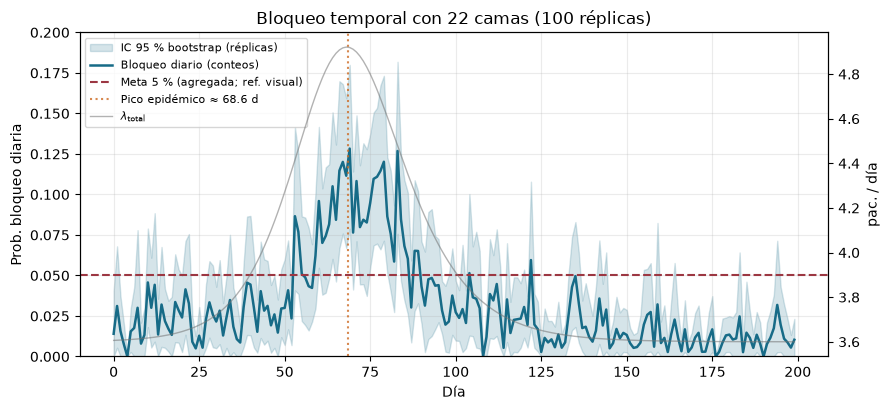

Fracción desviados (media réplicas): 0.0347 IC95 [0.0319, 0.0376]
Fracción agregada 100 rep (descriptiva): 0.0349
Desviados/réplica: 27.19 [24.87, 29.51]
Bloqueo máx diario: 0.1283 en día 69; en pico epidémico (día 69): 0.1283


In [5]:
print(f'Simulando {N_REPS} réplicas con c={C_BASE}...', flush=True)
df_rep22, L22, D22, A22 = run_capacity(C_BASE, packs, seeds)
assert np.all(A22 + D22 == L22)
df_rep22.to_csv(OUT / 'task4_replicas_22camas.csv', index=False)

fracs = df_rep22['fraccion_desviados'].to_numpy()
ic_frac = ic95_t(fracs)
ic_desv = ic95_t(df_rep22['desviados'].to_numpy())
# cociente agregado (descriptivo; NO es una réplica)
tot_L = int(L22.sum()); tot_D = int(D22.sum())
frac_agregada = tot_D / tot_L

# Bloqueo diario: razón de totales entre réplicas + bootstrap de réplicas
n_boot = 1000
rng_boot = np.random.default_rng(MASTER_SEED + 99)
bloqueo_punto = np.full(200, np.nan)
bloqueo_lo = np.full(200, np.nan)
bloqueo_hi = np.full(200, np.nan)
for d in range(200):
    Ld, Dd = L22[:, d], D22[:, d]
    if Ld.sum() == 0:
        continue
    bloqueo_punto[d] = Dd.sum() / Ld.sum()
    idx = rng_boot.integers(0, N_REPS, size=(n_boot, N_REPS))
    num = Dd[idx].sum(axis=1)
    den = Ld[idx].sum(axis=1)
    ratios = np.where(den > 0, num / den, np.nan)
    bloqueo_lo[d], bloqueo_hi[d] = np.nanpercentile(ratios, [2.5, 97.5])

day_peak = int(round(t_pico))
day_peak = min(max(day_peak, 0), 199)
imax = int(np.nanargmax(bloqueo_punto))

df_diario = pd.DataFrame({
    'dia': np.arange(200),
    'llegadas_totales_100rep': L22.sum(axis=0),
    'desviados_totales_100rep': D22.sum(axis=0),
    'bloqueo': bloqueo_punto,
    'bloqueo_IC95_inf_boot': bloqueo_lo,
    'bloqueo_IC95_sup_boot': bloqueo_hi,
    'lambda_total': lambda_total(np.arange(200) + 0.5),
})
df_diario.to_csv(OUT / 'task4_bloqueo_diario_22camas.csv', index=False)

resumen22 = pd.DataFrame([{
    'camas': C_BASE,
    'fraccion_media': ic_frac['media'],
    'fraccion_IC95_inf': ic_frac['inferior'],
    'fraccion_IC95_sup': ic_frac['superior'],
    'fraccion_agregada_100rep': frac_agregada,
    'desviados_media_por_replica': ic_desv['media'],
    'desviados_IC95_inf': ic_desv['inferior'],
    'desviados_IC95_sup': ic_desv['superior'],
    'desviados_suma_100rep_descriptivo': tot_D,
    'llegadas_suma_100rep_descriptivo': tot_L,
    'bloqueo_max_diario': float(bloqueo_punto[imax]),
    'dia_bloqueo_max': imax,
    'bloqueo_dia_pico_epidemiico': float(bloqueo_punto[day_peak]),
    'dia_pico_epidemiico_redondeado': day_peak,
}])
display(df_rep22.head())
display(resumen22)

fig, ax1 = plt.subplots(figsize=(9, 4.2))
d = df_diario['dia']
ax1.fill_between(d, df_diario['bloqueo_IC95_inf_boot'], df_diario['bloqueo_IC95_sup_boot'],
                  color='#176b87', alpha=.18, label='IC 95 % bootstrap (réplicas)')
ax1.plot(d, df_diario['bloqueo'], color='#176b87', lw=1.8, label='Bloqueo diario (conteos)')
ax1.axhline(META_DESVIO, color='#9c3742', ls='--', label='Meta 5 % (agregada; ref. visual)')
ax1.axvline(t_pico, color='#cd6b23', ls=':', alpha=.8, label=f'Pico epidémico ≈ {t_pico:.1f} d')
ax1.set_xlabel('Día'); ax1.set_ylabel('Prob. bloqueo diaria')
ax1.set_ylim(0, max(0.15, np.nanmax(bloqueo_hi) * 1.1))
ax2 = ax1.twinx()
ax2.plot(d, df_diario['lambda_total'], color='0.45', alpha=.55, lw=1, label=r'$\lambda_{\mathrm{total}}$')
ax2.set_ylabel('pac. / día')
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, fontsize=8, loc='upper left')
ax1.set_title(f'Bloqueo temporal con {C_BASE} camas (100 réplicas)')
ax1.grid(alpha=.25)
fig.tight_layout()
fig.savefig(OUT / 'task4_bloqueo_tiempo.png', dpi=150)
fig.savefig('figuras/task4_bloqueo_tiempo.png', dpi=150)
plt.show()

print(f"Fracción desviados (media réplicas): {ic_frac['media']:.4f} "
      f"IC95 [{ic_frac['inferior']:.4f}, {ic_frac['superior']:.4f}]")
print(f'Fracción agregada 100 rep (descriptiva): {frac_agregada:.4f}')
print(f"Desviados/réplica: {ic_desv['media']:.2f} "
      f"[{ic_desv['inferior']:.2f}, {ic_desv['superior']:.2f}]")
print(f'Bloqueo máx diario: {bloqueo_punto[imax]:.4f} en día {imax}; '
      f'en pico epidémico (día {day_peak}): {bloqueo_punto[day_peak]:.4f}')


## Task 4.1(c) — Camas de contingencia (meta 5 % agregado)

Se busca la menor $c\ge 22$ con fracción media de desvíos $\le 0.05$ en 100 réplicas (mismas llegadas CRN). También se reporta la menor $c$ cuyo **IC95 superior** $\le 0.05$ (criterio conservador).


Capacidad c=22...


Capacidad c=23...


,camas,camas_adicionales,fraccion_media,IC95_inferior,IC95_superior,desviados_medios,cumple_media,cumple_limite_superior
0,22,0,0.034725,0.031883,0.037567,27.19,True,True
1,23,1,0.024397,0.021973,0.026822,19.12,True,True


c_min_media=22 (+0); c_min_IC_superior=22 (+0)


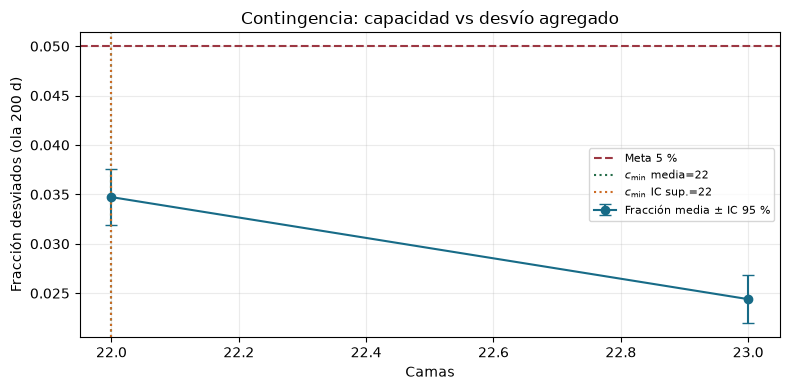

Durante la ola SIR de 200 días, con las 22 camas recomendadas en el Task 3.1 (variante sin espera, meta ordinaria 2 %), la fracción media de pacientes desviados fue 3.47 % (IC95 [3.19, 3.76] %), con 27.2 desviados por réplica en promedio. Para no superar el 5 % agregado de desvíos, la menor capacidad con media ≤ 5 % es c=22 (0 camas adicionales sobre 22). Con el criterio conservador (IC95 superior ≤ 5 %), se requieren c=22 (+0); en esa capacidad la fracción media es 3.47 % (IC95 [3.19, 3.76] %). La meta epidémica (5 % agregado) no debe confundirse con la meta ordinaria de bloqueo del 2 % del Task 3. Recomendación a la dirección: con el criterio agregado de 5 %, no es necesario comprar camas de contingencia adicionales sobre las 22; sí conviene monitorear el bloqueo diario en el pico, que puede superar el 5 % puntual.


In [6]:
filas_cap = []
resultados_c = {}
c = C_BASE
c_min_media = None
c_min_ic = None
# explorar hasta encontrar ambos criterios (con al menos c_min-1 visible)
while c <= C_BASE + 30:
    print(f'Capacidad c={c}...', flush=True)
    df_r, L, D, A = run_capacity(c, packs, seeds)
    ic = ic95_t(df_r['fraccion_desviados'].to_numpy())
    ic_d = ic95_t(df_r['desviados'].to_numpy())
    cumple_m = ic['media'] <= META_DESVIO
    cumple_s = ic['superior'] <= META_DESVIO
    filas_cap.append(dict(
        camas=c, camas_adicionales=c - C_BASE,
        fraccion_media=ic['media'], IC95_inferior=ic['inferior'], IC95_superior=ic['superior'],
        desviados_medios=ic_d['media'], cumple_media=cumple_m, cumple_limite_superior=cumple_s,
    ))
    resultados_c[c] = dict(df=df_r, ic=ic)
    if cumple_m and c_min_media is None:
        c_min_media = c
    if cumple_s and c_min_ic is None:
        c_min_ic = c
    # seguir un poco tras encontrar el conservador, o si aún no cumple media
    if c_min_media is not None and c_min_ic is not None and c >= c_min_ic + 1:
        break
    if c_min_media is not None and c >= c_min_media + 3 and c_min_ic is None:
        # aún no cumple IC; seguir
        pass
    c += 1

df_cap = pd.DataFrame(filas_cap)
# asegurar que se muestra al menos c_min-1 y c_min
assert c_min_media is not None, 'No se halló capacidad con media ≤ 5 %'
df_cap.to_csv(OUT / 'task4_capacidad_contingencia.csv', index=False)
display(df_cap)

adicionales_media = c_min_media - C_BASE
adicionales_ic = (c_min_ic - C_BASE) if c_min_ic is not None else None
print(f'c_min_media={c_min_media} (+{adicionales_media}); '
      f'c_min_IC_superior={c_min_ic} (+{adicionales_ic})')

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(df_cap['camas'], df_cap['fraccion_media'],
            yerr=[df_cap['fraccion_media'] - df_cap['IC95_inferior'],
                  df_cap['IC95_superior'] - df_cap['fraccion_media']],
            fmt='o-', color='#176b87', capsize=4, label='Fracción media ± IC 95 %')
ax.axhline(META_DESVIO, color='#9c3742', ls='--', label='Meta 5 %')
ax.axvline(c_min_media, color='#256d49', ls=':', label=f'$c_{{\\min}}$ media={c_min_media}')
if c_min_ic is not None:
    ax.axvline(c_min_ic, color='#cd6b23', ls=':', label=f'$c_{{\\min}}$ IC sup.={c_min_ic}')
ax.set(xlabel='Camas', ylabel='Fracción desviados (ola 200 d)',
       title='Contingencia: capacidad vs desvío agregado')
ax.grid(alpha=.25); ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / 'task4_capacidad_vs_bloqueo.png', dpi=150)
fig.savefig('figuras/task4_capacidad_vs_bloqueo.png', dpi=150)
plt.show()

# Texto automático para el informe
ic_m = resultados_c[c_min_media]['ic']
texto = (
    f"Durante la ola SIR de 200 días, con las {C_BASE} camas recomendadas en el Task 3.1 "
    f"(variante sin espera, meta ordinaria 2 %), la fracción media de pacientes desviados "
    f"fue {ic_frac['media']*100:.2f} % (IC95 [{ic_frac['inferior']*100:.2f}, "
    f"{ic_frac['superior']*100:.2f}] %), con {ic_desv['media']:.1f} desviados por réplica "
    f"en promedio. Para no superar el 5 % agregado de desvíos, la menor capacidad con "
    f"media ≤ 5 % es c={c_min_media} ({adicionales_media} camas adicionales sobre 22). "
)
if c_min_ic is not None:
    ic_c = resultados_c[c_min_ic]['ic']
    texto += (
        f"Con el criterio conservador (IC95 superior ≤ 5 %), se requieren c={c_min_ic} "
        f"(+{adicionales_ic}); en esa capacidad la fracción media es {ic_c['media']*100:.2f} % "
        f"(IC95 [{ic_c['inferior']*100:.2f}, {ic_c['superior']*100:.2f}] %). "
    )
else:
    texto += "El criterio conservador del IC superior no se alcanzó en el rango explorado. "
if adicionales_media == 0 and (adicionales_ic is None or adicionales_ic == 0):
    texto += (
        "La meta epidémica (5 % agregado) no debe confundirse con la meta ordinaria de bloqueo "
        "del 2 % del Task 3. Recomendación a la dirección: con el criterio agregado de 5 %, "
        "no es necesario comprar camas de contingencia adicionales sobre las 22; "
        "sí conviene monitorear el bloqueo diario en el pico, que puede superar el 5 % puntual."
    )
else:
    lo = adicionales_media if c_min_ic is None else min(adicionales_media, adicionales_ic)
    hi = adicionales_media if c_min_ic is None else max(adicionales_media, adicionales_ic)
    texto += (
        f"La meta epidémica (5 % agregado) no debe confundirse con la meta ordinaria de bloqueo "
        f"del 2 % del Task 3. Recomendación a la dirección: dimensionar contingencia en "
        f"{lo}–{hi} camas extra según el apetito de riesgo (media vs límite superior del IC)."
    )
print(texto)
